# Phase 5 — Revenue Forecasting

This phase extends the customer-retention analysis from individual churn risk to forward-looking business planning.

Historical merchandise revenue is used to forecast revenue over approximately the next three months.

The forecasting workflow first determines whether **daily or weekly revenue** provides the most appropriate modeling granularity based on sparsity and volatility.

The selected series is then used to:

- establish a seasonal-naive benchmark;
- evaluate ETS and ARIMA/SARIMA forecasting approaches;
- evaluate a LightGBM model using lag and rolling features;
- compare models using rolling-origin validation;
- measure forecast accuracy using MAE, RMSE, and sMAPE;
- generate the final three-month revenue forecast.

Because the dataset contains only about two years of transaction history, the amount of seasonal behavior that can be learned reliably is limited. Model complexity is therefore evaluated carefully against simple forecasting baselines.

## 5.1 Forecast Granularity Selection

Before fitting forecasting models, daily and weekly merchandise-revenue series are compared.

The project specification allows either daily or weekly forecasting, with the final frequency determined from the observed data rather than selected in advance.

The comparison considers:

- the number of available observations;
- the share of periods with zero revenue;
- relative revenue variability;
- period-to-period volatility.

Daily data provides more observations but may contain substantial short-term noise and calendar effects.

Weekly aggregation reduces day-to-day noise while retaining substantially more observations than monthly aggregation, which is important because the dataset contains only about two years of history.

Weeks are defined as **Saturday through Friday** so that the final transaction date, Friday 9 December 2011, completes a full weekly observation.

In [12]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sqlalchemy import create_engine, text
from dotenv import load_dotenv


PROJECT_ROOT = Path.cwd().parent

load_dotenv(
    PROJECT_ROOT / ".env"
)


DATABASE_URL = (
    f"postgresql+psycopg2://{os.getenv('DB_USER')}:"
    f"{os.getenv('DB_PASSWORD')}@"
    f"{os.getenv('DB_HOST')}:"
    f"{os.getenv('DB_PORT')}/"
    f"{os.getenv('DB_NAME')}"
)

engine = create_engine(
    DATABASE_URL
)


# Aggregate the cleaned merchandise transactions
# to one observation per calendar day.
daily_revenue_query = text(
    """
    SELECT
        invoice_date::date AS date,
        SUM(line_revenue) AS revenue,
        COUNT(DISTINCT invoice) AS orders,
        COUNT(*) AS transaction_lines
    FROM retail_transactions
    GROUP BY 1
    ORDER BY 1;
    """
)


daily_raw = pd.read_sql(
    daily_revenue_query,
    engine,
)


daily_raw["date"] = pd.to_datetime(
    daily_raw["date"]
)

daily_raw["revenue"] = pd.to_numeric(
    daily_raw["revenue"]
)


# Build a complete daily calendar.
# Dates with no qualifying merchandise sales
# are represented with zero revenue.
full_calendar = pd.date_range(
    start=daily_raw["date"].min(),
    end=daily_raw["date"].max(),
    freq="D",
)


daily_revenue = (
    daily_raw
    .set_index("date")
    .reindex(full_calendar)
)

daily_revenue.index.name = "date"

daily_revenue[
    [
        "revenue",
        "orders",
        "transaction_lines",
    ]
] = daily_revenue[
    [
        "revenue",
        "orders",
        "transaction_lines",
    ]
].fillna(0)

daily_revenue = daily_revenue.reset_index()


# Aggregate daily revenue into Saturday-Friday weeks.
weekly_revenue = (
    daily_revenue
    .set_index("date")
    .resample("W-FRI")
    .agg(
        revenue=("revenue", "sum"),
        calendar_days=("revenue", "size"),
    )
    .reset_index()
    .rename(
        columns={
            "date": "week_end",
        }
    )
)


# Remove only incomplete edge weeks.
weekly_revenue = (
    weekly_revenue.loc[
        weekly_revenue["calendar_days"] == 7
    ]
    .copy()
    .reset_index(drop=True)
)


def series_diagnostics(values):
    values = pd.Series(
        values,
        dtype=float,
    )

    return {
        "observations": len(values),
        "zero_revenue_share": (
            values.eq(0).mean()
        ),
        "coefficient_of_variation": (
            values.std() / values.mean()
        ),
        "mean_abs_change_ratio": (
            values.diff().abs().dropna().mean()
            / values.mean()
        ),
    }


granularity_comparison = pd.DataFrame(
    [
        {
            "granularity": "Daily",
            **series_diagnostics(
                daily_revenue["revenue"]
            ),
        },
        {
            "granularity": "Weekly",
            **series_diagnostics(
                weekly_revenue["revenue"]
            ),
        },
    ]
)


print(
    "Daily date range:",
    daily_revenue["date"].min().date(),
    "to",
    daily_revenue["date"].max().date(),
)

print(
    "Complete weekly date range:",
    weekly_revenue["week_end"].min().date(),
    "to",
    weekly_revenue["week_end"].max().date(),
)

print(
    "Complete weekly observations:",
    len(weekly_revenue),
)


display(
    granularity_comparison.round(4)
)

Daily date range: 2009-12-01 to 2011-12-09
Complete weekly date range: 2009-12-11 to 2011-12-09
Complete weekly observations: 105


,granularity,observations,zero_revenue_share,coefficient_of_variation,mean_abs_change_ratio
0,Daily,739,0.1827,0.7759,0.6172
1,Weekly,105,0.0190,0.4121,0.2389


### Forecast Granularity — Decision

Weekly revenue is selected as the forecasting frequency.

The daily series contains **739 observations**, but it is relatively sparse and volatile:

- **18.27%** of calendar days have zero qualifying merchandise revenue;
- coefficient of variation = **0.7759**;
- mean absolute day-to-day change equals approximately **61.72%** of average daily revenue.

Weekly aggregation substantially stabilizes the series while retaining enough observations for time-series and machine-learning forecasting:

- **105 complete weekly observations**;
- only **1.90%** of weeks have zero revenue;
- coefficient of variation = **0.4121**;
- mean absolute week-to-week change equals approximately **23.89%** of average weekly revenue.

Weekly forecasting therefore provides a better balance between sample size and noise reduction than either daily or monthly aggregation.

Weeks are defined from **Saturday through Friday**. The first incomplete edge week is excluded, leaving a continuous complete-week series from **11 December 2009 through 9 December 2011**.

The final forecasting horizon will cover approximately the next three months, corresponding to **13 weekly periods**.

## 5.2 Weekly Revenue Pattern

The selected weekly revenue series is inspected before model development.

The objective is to identify:

- overall revenue movement;
- seasonal peaks and troughs;
- unusual weeks;
- whether annual seasonal behavior remains visible at the weekly level.

The series contains 105 complete weeks, providing substantially more modeling observations than monthly aggregation while smoothing much of the daily volatility.

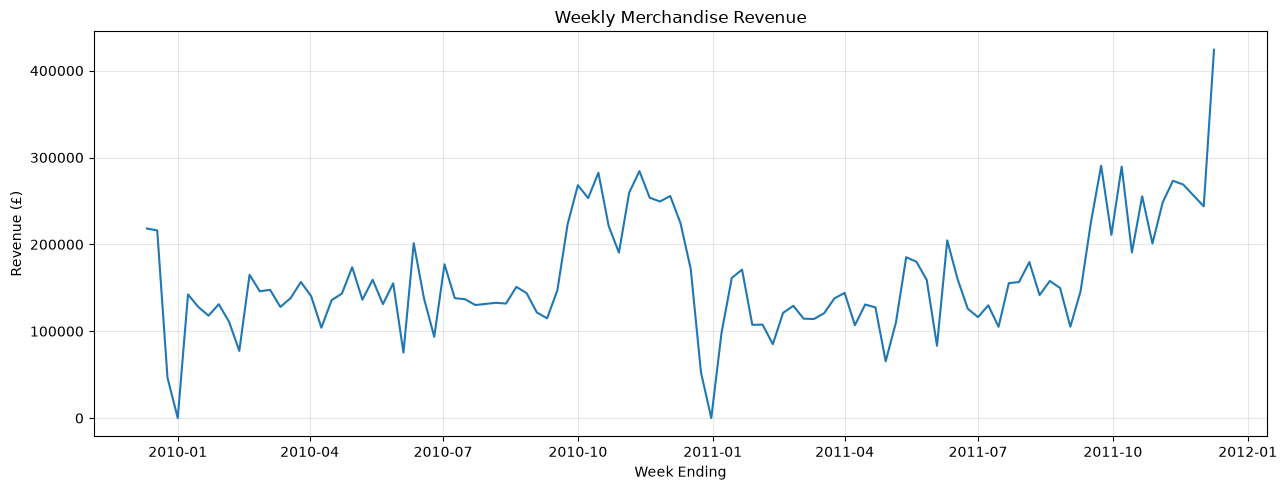

Mean weekly revenue: £160,721.62
Median weekly revenue: £144,136.62
Minimum weekly revenue: £0.00
Maximum weekly revenue: £424,064.25


In [13]:
plt.figure(
    figsize=(13, 5)
)

plt.plot(
    weekly_revenue["week_end"],
    weekly_revenue["revenue"],
    linewidth=1.5,
)

plt.title(
    "Weekly Merchandise Revenue"
)

plt.xlabel(
    "Week Ending"
)

plt.ylabel(
    "Revenue (£)"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


print(
    "Mean weekly revenue:",
    f"£{weekly_revenue['revenue'].mean():,.2f}",
)

print(
    "Median weekly revenue:",
    f"£{weekly_revenue['revenue'].median():,.2f}",
)

print(
    "Minimum weekly revenue:",
    f"£{weekly_revenue['revenue'].min():,.2f}",
)

print(
    "Maximum weekly revenue:",
    f"£{weekly_revenue['revenue'].max():,.2f}",
)

### Weekly Revenue — Interpretation

The selected weekly series contains **105 complete observations**.

Weekly merchandise revenue has:

- **Mean:** £160,721.62
- **Median:** £144,136.62
- **Minimum:** £0.00
- **Maximum:** £424,064.25

The mean exceeds the median, indicating that several high-revenue weeks pull the average upward.

The weekly series retains meaningful variation while being substantially less volatile than the daily series. Strong revenue increases remain visible toward the end of both years, suggesting that annual seasonality is still present at the weekly level.

A small number of complete calendar weeks contain zero qualifying merchandise revenue. These observations are retained rather than treated as missing values because they are part of the continuous calendar series.

### 5.2.1 Annual Weekly Seasonality

Annual seasonality is evaluated using a 52-week lag.

For every week with sufficient history, current revenue is paired with revenue from **52 weeks earlier**.

A strong positive relationship would support using a 52-week seasonal-naive forecast as an important benchmark.

This is an exploratory seasonality check only. Final model selection will still be based on chronological rolling-origin validation.

In [14]:
weekly_seasonality = weekly_revenue[
    [
        "week_end",
        "revenue",
    ]
].copy()


weekly_seasonality["revenue_lag_52"] = (
    weekly_seasonality["revenue"].shift(52)
)


seasonal_pairs = (
    weekly_seasonality
    .dropna()
    .copy()
)


lag_52_correlation = seasonal_pairs[
    [
        "revenue",
        "revenue_lag_52",
    ]
].corr().iloc[0, 1]


seasonal_pairs["absolute_difference"] = np.abs(
    seasonal_pairs["revenue"]
    - seasonal_pairs["revenue_lag_52"]
)


print(
    "Comparable week pairs:",
    len(seasonal_pairs),
)

print(
    "52-week revenue correlation:",
    f"{lag_52_correlation:.3f}",
)

print(
    "Mean absolute 52-week difference:",
    f"£{seasonal_pairs['absolute_difference'].mean():,.2f}",
)

print(
    "Median absolute 52-week difference:",
    f"£{seasonal_pairs['absolute_difference'].median():,.2f}",
)

Comparable week pairs: 53
52-week revenue correlation: 0.785
Mean absolute 52-week difference: £29,656.71
Median absolute 52-week difference: £18,816.49


#### Annual Weekly Seasonality — Interpretation

The 52-week lag comparison provides **53 comparable weekly pairs**.

Revenue in corresponding weeks one year apart has a correlation of:

**0.785**

This indicates a meaningful recurring annual pattern at the weekly level, although the relationship is weaker than the broad monthly seasonal pattern observed earlier.

The typical difference between corresponding weeks is:

- **Mean absolute difference:** £29,656.71
- **Median absolute difference:** £18,816.49

Annual seasonality is therefore an important forecasting signal, but weekly revenue does not repeat exactly from year to year.

A **52-week Seasonal Naive** model will consequently be used as the primary baseline, while statistical and machine-learning models will be tested to determine whether they can improve on this seasonal benchmark.

## 5.3 Rolling-Origin Forecast Validation

Forecast models are evaluated using rolling-origin validation.

A random train/test split would leak future information and is therefore inappropriate for time-series forecasting.

The business forecast horizon is approximately three months, so each validation fold predicts the following **13 weeks**.

Four expanding-window folds are used. Each new fold adds the previous 13-week evaluation period to the training history.

This design:

- preserves chronological order;
- evaluates forecasts during different parts of the year;
- provides multiple out-of-sample forecast periods;
- allows every test week to have at least 52 weeks of prior history for the seasonal-naive benchmark.

Models will be compared using:

- **MAE** — average absolute forecast error in pounds;
- **RMSE** — penalizes larger forecast errors more strongly;
- **sMAPE** — percentage error scaled relative to both actual and predicted revenue.

Lower values indicate better forecast performance.

In [15]:
forecast_horizon_weeks = 13

# Expanding training windows.
# 53 weeks gives the first forecast period access
# to a full 52-week seasonal history.
training_sizes = [
    53,
    66,
    79,
    92,
]


weekly_backtest_folds = []

for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    train_data = weekly_revenue.iloc[
        :train_size
    ].copy()

    test_data = weekly_revenue.iloc[
        train_size:
        train_size + forecast_horizon_weeks
    ].copy()

    weekly_backtest_folds.append(
        {
            "fold": fold_number,
            "train_start": train_data["week_end"].min(),
            "train_end": train_data["week_end"].max(),
            "train_weeks": len(train_data),
            "forecast_start": test_data["week_end"].min(),
            "forecast_end": test_data["week_end"].max(),
            "forecast_weeks": len(test_data),
        }
    )


weekly_backtest_summary = pd.DataFrame(
    weekly_backtest_folds
)

weekly_backtest_summary

,fold,train_start,train_end,train_weeks,forecast_start,forecast_end,forecast_weeks
0,1,2009-12-11,2010-12-10,53,2010-12-17,2011-03-11,13
1,2,2009-12-11,2011-03-11,66,2011-03-18,2011-06-10,13
2,3,2009-12-11,2011-06-10,79,2011-06-17,2011-09-09,13
3,4,2009-12-11,2011-09-09,92,2011-09-16,2011-12-09,13


### Rolling-Origin Validation — Interpretation

The backtesting design contains four expanding-window folds.

Each fold forecasts the following **13 weeks**, giving **52 out-of-sample weekly predictions** across the full evaluation.

The training window expands after each fold:

- Fold 1: 53 training weeks
- Fold 2: 66 training weeks
- Fold 3: 79 training weeks
- Fold 4: 92 training weeks

Every evaluation period occurs strictly after its corresponding training period, preventing future information from leaking into model development.

The first training window also contains sufficient history for a 52-week seasonal-naive forecast.

### 5.3.1 Seasonal-Naive Baseline

The primary forecasting baseline predicts each future week's revenue using revenue from **52 weeks earlier**.

This benchmark directly represents the annual seasonal pattern identified during exploratory analysis.

A more complex forecasting model should only be preferred if it produces a meaningful improvement over this simple and interpretable seasonal rule.

In [18]:
def smape(actual, predicted):
    actual = np.asarray(
        actual,
        dtype=float,
    )

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    denominator = (
        np.abs(actual)
        + np.abs(predicted)
    )

    individual_errors = np.zeros_like(
        denominator,
        dtype=float,
    )

    nonzero_mask = (
        denominator != 0
    )

    individual_errors[
        nonzero_mask
    ] = (
        2
        * np.abs(
            actual[nonzero_mask]
            - predicted[nonzero_mask]
        )
        / denominator[nonzero_mask]
    )

    return (
        individual_errors.mean()
        * 100
    )


seasonal_naive_predictions = []


for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    test_data = weekly_revenue.iloc[
        train_size:
        train_size + forecast_horizon_weeks
    ].copy()

    test_positions = np.arange(
        train_size,
        train_size + len(test_data),
    )

    seasonal_predictions = (
        weekly_revenue.iloc[
            test_positions - 52
        ]["revenue"]
        .to_numpy()
    )


    for week_end, actual, prediction in zip(
        test_data["week_end"],
        test_data["revenue"],
        seasonal_predictions,
    ):
        seasonal_naive_predictions.append(
            {
                "fold": fold_number,
                "week_end": week_end,
                "actual": actual,
                "prediction": prediction,
            }
        )


seasonal_naive_results = pd.DataFrame(
    seasonal_naive_predictions
)


seasonal_naive_results["absolute_error"] = np.abs(
    seasonal_naive_results["actual"]
    - seasonal_naive_results["prediction"]
)

seasonal_naive_results["squared_error"] = (
    seasonal_naive_results["actual"]
    - seasonal_naive_results["prediction"]
) ** 2


seasonal_naive_mae = (
    seasonal_naive_results[
        "absolute_error"
    ].mean()
)

seasonal_naive_rmse = np.sqrt(
    seasonal_naive_results[
        "squared_error"
    ].mean()
)

seasonal_naive_smape = smape(
    seasonal_naive_results["actual"],
    seasonal_naive_results["prediction"],
)


print(
    "Seasonal Naive MAE:",
    f"£{seasonal_naive_mae:,.2f}",
)

print(
    "Seasonal Naive RMSE:",
    f"£{seasonal_naive_rmse:,.2f}",
)

print(
    "Seasonal Naive sMAPE:",
    f"{seasonal_naive_smape:.2f}%",
)

print(
    "Forecast weeks evaluated:",
    len(seasonal_naive_results),
)

Seasonal Naive MAE: £30,106.90
Seasonal Naive RMSE: £44,972.90
Seasonal Naive sMAPE: 18.22%
Forecast weeks evaluated: 52


#### Seasonal-Naive Baseline — Overall Performance

Across **52 out-of-sample weekly forecasts**, the 52-week seasonal-naive benchmark achieved:

- **MAE:** £30,106.90
- **RMSE:** £44,972.90
- **sMAPE:** 18.22%

These values establish the benchmark that ETS, ARIMA/SARIMA, and LightGBM must improve upon.

The baseline already captures the retailer's recurring annual revenue pattern, so more complex models will only be retained if they provide stronger chronological forecast accuracy.

In [19]:
seasonal_fold_results = (
    seasonal_naive_results
    .groupby("fold")
    .apply(
        lambda group: pd.Series(
            {
                "forecast_start": group["week_end"].min(),
                "forecast_end": group["week_end"].max(),
                "MAE": group["absolute_error"].mean(),
                "RMSE": np.sqrt(
                    group["squared_error"].mean()
                ),
                "sMAPE": smape(
                    group["actual"],
                    group["prediction"],
                ),
            }
        ),
        include_groups=False,
    )
    .reset_index()
)


seasonal_fold_results["MAE"] = (
    seasonal_fold_results["MAE"]
    .round(2)
)

seasonal_fold_results["RMSE"] = (
    seasonal_fold_results["RMSE"]
    .round(2)
)

seasonal_fold_results["sMAPE"] = (
    seasonal_fold_results["sMAPE"]
    .round(2)
)


seasonal_fold_results

,fold,forecast_start,forecast_end,MAE,RMSE,sMAPE
0,1,2010-12-17,2011-03-11,24881.08,30415.96,18.73
1,2,2011-03-18,2011-06-10,22149.14,35630.82,16.87
2,3,2011-06-17,2011-09-09,24845.55,29382.20,18.27
3,4,2011-09-16,2011-12-09,48551.82,70938.34,19.01


#### Seasonal-Naive Fold Consistency

The seasonal-naive benchmark performs reasonably consistently across the four chronological forecast windows.

Fold-level sMAPE ranges only from **16.87% to 19.01%**, indicating that percentage forecast accuracy is relatively stable across different parts of the year.

The fourth fold, covering September through December 2011, has substantially higher MAE and RMSE:

- **MAE:** £48,551.82
- **RMSE:** £70,938.34

This period contains some of the retailer's highest-revenue weeks, so errors measured in pounds are naturally larger even though relative percentage accuracy remains similar.

The seasonal-naive benchmark therefore provides a strong and reasonably stable reference for evaluating more complex forecasting models.

## 5.4 ETS Forecasting

Exponential-smoothing models are evaluated as the first statistical forecasting alternatives.

A full weekly seasonal ETS model with a 52-week seasonal period is not estimated during model selection because the rolling training windows contain fewer than two complete annual cycles.

Estimating 52 independent seasonal effects from such limited history would be unstable and would make the comparison unreliable.

Instead, three parsimonious ETS-family specifications are evaluated:

- **Level-only exponential smoothing**
- **Additive Holt trend**
- **Damped additive Holt trend**

Annual seasonality remains represented explicitly by the 52-week seasonal-naive benchmark.

All ETS models use the same four rolling-origin folds and 13-week forecast horizon.

In [20]:
from statsmodels.tsa.holtwinters import (
    ExponentialSmoothing,
)


ets_predictions = []


for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    train_data = weekly_revenue.iloc[
        :train_size
    ].copy()

    test_data = weekly_revenue.iloc[
        train_size:
        train_size + forecast_horizon_weeks
    ].copy()

    y_train = (
        train_data["revenue"]
        .astype(float)
        .to_numpy()
    )


    # ETS: level only
    level_model = ExponentialSmoothing(
        y_train,
        trend=None,
        seasonal=None,
        initialization_method="estimated",
    ).fit(
        optimized=True
    )

    level_forecast = level_model.forecast(
        len(test_data)
    )


    # ETS: additive trend
    trend_model = ExponentialSmoothing(
        y_train,
        trend="add",
        seasonal=None,
        initialization_method="estimated",
    ).fit(
        optimized=True
    )

    trend_forecast = trend_model.forecast(
        len(test_data)
    )


    # ETS: damped additive trend
    damped_model = ExponentialSmoothing(
        y_train,
        trend="add",
        damped_trend=True,
        seasonal=None,
        initialization_method="estimated",
    ).fit(
        optimized=True
    )

    damped_forecast = damped_model.forecast(
        len(test_data)
    )


    forecasts = {
        "ETS Level Only": level_forecast,
        "ETS Additive Trend": trend_forecast,
        "ETS Damped Trend": damped_forecast,
    }


    for model_name, predictions in forecasts.items():
        for week_end, actual, prediction in zip(
            test_data["week_end"],
            test_data["revenue"],
            predictions,
        ):
            ets_predictions.append(
                {
                    "fold": fold_number,
                    "week_end": week_end,
                    "model": model_name,
                    "actual": actual,
                    "prediction": prediction,
                }
            )


ets_results = pd.DataFrame(
    ets_predictions
)


ets_results["absolute_error"] = np.abs(
    ets_results["actual"]
    - ets_results["prediction"]
)

ets_results["squared_error"] = (
    ets_results["actual"]
    - ets_results["prediction"]
) ** 2


ets_summary_rows = []

for model_name, group in ets_results.groupby(
    "model"
):
    ets_summary_rows.append(
        {
            "model": model_name,
            "MAE": group[
                "absolute_error"
            ].mean(),
            "RMSE": np.sqrt(
                group[
                    "squared_error"
                ].mean()
            ),
            "sMAPE": smape(
                group["actual"],
                group["prediction"],
            ),
        }
    )


ets_summary = (
    pd.DataFrame(
        ets_summary_rows
    )
    .sort_values("sMAPE")
    .reset_index(drop=True)
)


ets_summary["MAE"] = (
    ets_summary["MAE"]
    .round(2)
)

ets_summary["RMSE"] = (
    ets_summary["RMSE"]
    .round(2)
)

ets_summary["sMAPE"] = (
    ets_summary["sMAPE"]
    .round(2)
)


ets_summary

,model,MAE,RMSE,sMAPE
0,ETS Damped Trend,79384.10,101253.41,46.48
1,ETS Level Only,80321.10,101312.25,46.96
2,ETS Additive Trend,84506.51,108821.01,48.67


### ETS Performance — Interpretation

None of the evaluated ETS specifications outperform the 52-week seasonal-naive benchmark.

The strongest ETS model is **Damped Trend**, with:

- **MAE:** £79,384.10
- **RMSE:** £101,253.41
- **sMAPE:** 46.48%

For comparison, Seasonal Naive achieved:

- **MAE:** £30,106.90
- **RMSE:** £44,972.90
- **sMAPE:** 18.22%

The substantial performance gap indicates that weekly revenue cannot be forecast effectively from level and short-term trend alone.

The retailer's recurring annual seasonal pattern contains considerably more predictive information.

A full 52-week seasonal ETS specification is not forced onto the data because the available training windows contain fewer than two complete seasonal cycles, making estimation of a large weekly seasonal component unreliable.

## 5.5 ARIMA Forecasting

ARIMA models are evaluated to determine whether short-term autoregressive and moving-average structure can improve weekly revenue forecasts.

A deliberately small set of candidate orders is tested to limit overfitting:

- ARIMA(1,0,0)
- ARIMA(2,0,0)
- ARIMA(1,1,0)
- ARIMA(0,1,1)
- ARIMA(1,1,1)
- ARIMA(2,1,0)
- ARIMA(0,1,2)

A 52-week seasonal SARIMA component is not estimated because the available rolling training windows contain insufficient repeated annual cycles for reliable seasonal parameter estimation.

Each ARIMA specification is evaluated across the same four rolling-origin folds and 13-week forecast horizon.

Model selection is based on out-of-sample MAE, RMSE, and sMAPE rather than in-sample fit.

In [21]:
from statsmodels.tsa.arima.model import ARIMA
import warnings


arima_orders = [
    (1, 0, 0),
    (2, 0, 0),
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 0),
    (0, 1, 2),
]


arima_predictions = []


for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    train_data = weekly_revenue.iloc[
        :train_size
    ].copy()

    test_data = weekly_revenue.iloc[
        train_size:
        train_size + forecast_horizon_weeks
    ].copy()

    y_train = (
        train_data["revenue"]
        .astype(float)
        .to_numpy()
    )


    for order in arima_orders:
        model_name = (
            f"ARIMA{order}"
        )

        with warnings.catch_warnings():
            warnings.simplefilter(
                "ignore"
            )

            model = ARIMA(
                y_train,
                order=order,
            ).fit()


        predictions = model.forecast(
            steps=len(test_data)
        )


        # Revenue cannot be negative.
        predictions = np.maximum(
            predictions,
            0,
        )


        for week_end, actual, prediction in zip(
            test_data["week_end"],
            test_data["revenue"],
            predictions,
        ):
            arima_predictions.append(
                {
                    "fold": fold_number,
                    "week_end": week_end,
                    "model": model_name,
                    "actual": actual,
                    "prediction": prediction,
                }
            )


arima_results = pd.DataFrame(
    arima_predictions
)


arima_results["absolute_error"] = np.abs(
    arima_results["actual"]
    - arima_results["prediction"]
)

arima_results["squared_error"] = (
    arima_results["actual"]
    - arima_results["prediction"]
) ** 2


arima_summary_rows = []

for model_name, group in arima_results.groupby(
    "model"
):
    arima_summary_rows.append(
        {
            "model": model_name,
            "MAE": group[
                "absolute_error"
            ].mean(),
            "RMSE": np.sqrt(
                group[
                    "squared_error"
                ].mean()
            ),
            "sMAPE": smape(
                group["actual"],
                group["prediction"],
            ),
        }
    )


arima_summary = (
    pd.DataFrame(
        arima_summary_rows
    )
    .sort_values("sMAPE")
    .reset_index(drop=True)
)


arima_summary["MAE"] = (
    arima_summary["MAE"]
    .round(2)
)

arima_summary["RMSE"] = (
    arima_summary["RMSE"]
    .round(2)
)

arima_summary["sMAPE"] = (
    arima_summary["sMAPE"]
    .round(2)
)


arima_summary

,model,MAE,RMSE,sMAPE
0,"ARIMA(1, 0, 0)",56555.01,77595.31,35.63
1,"ARIMA(2, 0, 0)",57108.31,78011.51,35.87
2,"ARIMA(1, 1, 1)",74093.52,96588.93,43.19
3,"ARIMA(0, 1, 2)",75502.67,96985.11,44.25
4,"ARIMA(0, 1, 1)",78553.35,100787.63,45.87
5,"ARIMA(2, 1, 0)",79649.90,98681.38,46.64
6,"ARIMA(1, 1, 0)",81170.05,98069.14,47.95


### ARIMA Performance — Interpretation

The strongest ARIMA specification is **ARIMA(1,0,0)**, with:

- **MAE:** £56,555.01
- **RMSE:** £77,595.31
- **sMAPE:** 35.63%

This performs better than all evaluated ETS specifications but remains substantially weaker than the 52-week Seasonal Naive benchmark:

- **Seasonal Naive MAE:** £30,106.90
- **Seasonal Naive RMSE:** £44,972.90
- **Seasonal Naive sMAPE:** 18.22%

The two non-differenced autoregressive models, ARIMA(1,0,0) and ARIMA(2,0,0), perform better than the differenced alternatives.

However, short-term autoregressive structure alone does not capture the retailer's annual revenue pattern as effectively as simply using revenue from the corresponding week one year earlier.

Seasonal Naive therefore remains the leading model before evaluating the machine-learning approach.

## 5.6 LightGBM Forecasting with Lag Features

A LightGBM regression model is evaluated as the machine-learning forecasting approach.

Because only about two years of weekly history are available, the feature set is intentionally compact.

Each weekly prediction uses only information that would have been available before that week:

- revenue 1 week ago;
- revenue 2 weeks ago;
- revenue 4 weeks ago;
- revenue 13 weeks ago;
- rolling mean over the previous 4 weeks;
- rolling mean over the previous 13 weeks;
- rolling standard deviation over the previous 4 weeks;
- annual calendar position represented using sine and cosine transformations;
- a time index representing the long-term position of the observation.

A 52-week lag is not included in the LightGBM feature set because the earliest training fold contains only 53 weeks. Using that lag would leave almost no observations for model fitting.

The 52-week annual pattern is instead represented directly by the Seasonal Naive benchmark.

For multi-week forecasting, LightGBM predictions are generated recursively: each predicted week is added to the historical series before constructing features for the following forecast week.

In [22]:
from lightgbm import LGBMRegressor


def build_lightgbm_features(
    revenue_series,
    date_series,
):
    data = pd.DataFrame(
        {
            "week_end": pd.to_datetime(
                date_series
            ),
            "revenue": np.asarray(
                revenue_series,
                dtype=float,
            ),
        }
    ).reset_index(drop=True)


    # Lag features use only revenue from
    # periods before the target week.
    for lag in [
        1,
        2,
        4,
        13,
    ]:
        data[
            f"lag_{lag}"
        ] = data[
            "revenue"
        ].shift(lag)


    shifted_revenue = (
        data["revenue"]
        .shift(1)
    )


    data["rolling_mean_4"] = (
        shifted_revenue
        .rolling(4)
        .mean()
    )

    data["rolling_mean_13"] = (
        shifted_revenue
        .rolling(13)
        .mean()
    )

    data["rolling_std_4"] = (
        shifted_revenue
        .rolling(4)
        .std()
    )


    # Annual calendar position.
    week_number = (
        data["week_end"]
        .dt.isocalendar()
        .week
        .astype(float)
    )

    data["week_sin"] = np.sin(
        2
        * np.pi
        * week_number
        / 52.0
    )

    data["week_cos"] = np.cos(
        2
        * np.pi
        * week_number
        / 52.0
    )


    # Simple chronological trend index.
    data["time_index"] = np.arange(
        len(data)
    )


    return data


lightgbm_feature_data = (
    build_lightgbm_features(
        weekly_revenue["revenue"],
        weekly_revenue["week_end"],
    )
)


lightgbm_feature_columns = [
    "lag_1",
    "lag_2",
    "lag_4",
    "lag_13",
    "rolling_mean_4",
    "rolling_mean_13",
    "rolling_std_4",
    "week_sin",
    "week_cos",
    "time_index",
]


print(
    "Feature columns:",
    len(lightgbm_feature_columns),
)

print(
    "First row with complete features:",
    lightgbm_feature_data[
        lightgbm_feature_columns
    ]
    .dropna()
    .index.min(),
)


training_row_counts = []

for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    fold_training = (
        lightgbm_feature_data.iloc[
            :train_size
        ]
        .dropna(
            subset=lightgbm_feature_columns
            + ["revenue"]
        )
    )

    training_row_counts.append(
        {
            "fold": fold_number,
            "training_weeks": train_size,
            "usable_lightgbm_rows": len(
                fold_training
            ),
        }
    )


pd.DataFrame(
    training_row_counts
)

Feature columns: 10
First row with complete features: 13


,fold,training_weeks,usable_lightgbm_rows
0,1,53,40
1,2,66,53
2,3,79,66
3,4,92,79


### LightGBM Training Sample

After constructing leakage-safe lag and rolling features, the first 13 weeks are unavailable because they do not yet have sufficient historical information.

The usable training sample increases as the rolling window expands:

- **Fold 1:** 40 rows
- **Fold 2:** 53 rows
- **Fold 3:** 66 rows
- **Fold 4:** 79 rows

This is sufficient to evaluate a compact LightGBM model, but it remains a relatively small machine-learning dataset.

Model complexity is therefore restricted and no extensive hyperparameter search is performed. LightGBM performance should be interpreted in the context of this limited historical sample.

In [23]:
lightgbm_predictions = []


for fold_number, train_size in enumerate(
    training_sizes,
    start=1,
):
    train_data = weekly_revenue.iloc[
        :train_size
    ].copy()

    test_data = weekly_revenue.iloc[
        train_size:
        train_size + forecast_horizon_weeks
    ].copy()


    # Construct training features using
    # historical observations only.
    train_features = build_lightgbm_features(
        train_data["revenue"],
        train_data["week_end"],
    )

    train_features = train_features.dropna(
        subset=lightgbm_feature_columns
        + ["revenue"]
    )


    X_train = train_features[
        lightgbm_feature_columns
    ]

    y_train = train_features[
        "revenue"
    ]


    # Keep the model deliberately small because
    # the weekly training sample is limited.
    model = LGBMRegressor(
        objective="regression",
        n_estimators=150,
        learning_rate=0.05,
        num_leaves=7,
        max_depth=3,
        min_child_samples=5,
        reg_lambda=1.0,
        random_state=42,
        verbosity=-1,
    )


    model.fit(
        X_train,
        y_train,
    )


    # Begin recursive forecasting with only
    # revenue known at the forecast origin.
    history_revenue = (
        train_data["revenue"]
        .astype(float)
        .tolist()
    )

    history_dates = (
        train_data["week_end"]
        .tolist()
    )


    for _, test_row in test_data.iterrows():
        forecast_date = test_row[
            "week_end"
        ]


        # Add the future date with an unknown target.
        temporary_revenue = (
            history_revenue
            + [np.nan]
        )

        temporary_dates = (
            history_dates
            + [forecast_date]
        )


        future_features = build_lightgbm_features(
            temporary_revenue,
            temporary_dates,
        )


        X_next = future_features.loc[
            [
                future_features.index[-1]
            ],
            lightgbm_feature_columns,
        ]


        prediction = float(
            model.predict(
                X_next
            )[0]
        )


        # Revenue forecasts cannot be negative.
        prediction = max(
            prediction,
            0.0,
        )


        lightgbm_predictions.append(
            {
                "fold": fold_number,
                "week_end": forecast_date,
                "actual": float(
                    test_row["revenue"]
                ),
                "prediction": prediction,
            }
        )


        # The prediction becomes part of history
        # for the following recursive forecast.
        history_revenue.append(
            prediction
        )

        history_dates.append(
            forecast_date
        )


lightgbm_results = pd.DataFrame(
    lightgbm_predictions
)


lightgbm_results["absolute_error"] = np.abs(
    lightgbm_results["actual"]
    - lightgbm_results["prediction"]
)

lightgbm_results["squared_error"] = (
    lightgbm_results["actual"]
    - lightgbm_results["prediction"]
) ** 2


lightgbm_mae = (
    lightgbm_results[
        "absolute_error"
    ].mean()
)

lightgbm_rmse = np.sqrt(
    lightgbm_results[
        "squared_error"
    ].mean()
)

lightgbm_smape = smape(
    lightgbm_results["actual"],
    lightgbm_results["prediction"],
)


print(
    "LightGBM MAE:",
    f"£{lightgbm_mae:,.2f}",
)

print(
    "LightGBM RMSE:",
    f"£{lightgbm_rmse:,.2f}",
)

print(
    "LightGBM sMAPE:",
    f"{lightgbm_smape:.2f}%",
)

print(
    "Forecast weeks evaluated:",
    len(lightgbm_results),
)

LightGBM MAE: £60,541.55
LightGBM RMSE: £80,225.80
LightGBM sMAPE: 37.80%
Forecast weeks evaluated: 52


### LightGBM Performance — Interpretation

The LightGBM forecasting model achieved:

- **MAE:** £60,541.55
- **RMSE:** £80,225.80
- **sMAPE:** 37.80%

LightGBM performs better than the evaluated ETS models but does not outperform the strongest ARIMA specification or the 52-week Seasonal Naive benchmark.

The relatively small weekly training sample limits the amount of nonlinear structure that the model can learn reliably.

In addition, recursive forecasting compounds prediction uncertainty because each predicted week is used as part of the history for constructing later lag and rolling features.

The results therefore indicate that additional machine-learning complexity does not provide sufficient forecasting improvement for this dataset.

## 5.7 Final Model Comparison

The strongest specification from each forecasting family is compared using the same 52 out-of-sample weekly predictions.

The selected forecasting model is determined entirely from rolling-origin validation performance rather than model complexity.

In [24]:
best_ets = (
    ets_summary
    .sort_values("sMAPE")
    .iloc[0]
)

best_arima = (
    arima_summary
    .sort_values("sMAPE")
    .iloc[0]
)


model_comparison = pd.DataFrame(
    [
        {
            "model": "Seasonal Naive (52-week)",
            "MAE": seasonal_naive_mae,
            "RMSE": seasonal_naive_rmse,
            "sMAPE": seasonal_naive_smape,
        },
        {
            "model": best_arima["model"],
            "MAE": best_arima["MAE"],
            "RMSE": best_arima["RMSE"],
            "sMAPE": best_arima["sMAPE"],
        },
        {
            "model": "LightGBM",
            "MAE": lightgbm_mae,
            "RMSE": lightgbm_rmse,
            "sMAPE": lightgbm_smape,
        },
        {
            "model": best_ets["model"],
            "MAE": best_ets["MAE"],
            "RMSE": best_ets["RMSE"],
            "sMAPE": best_ets["sMAPE"],
        },
    ]
)


model_comparison = (
    model_comparison
    .sort_values("sMAPE")
    .reset_index(drop=True)
)


model_comparison["MAE"] = (
    model_comparison["MAE"]
    .astype(float)
    .round(2)
)

model_comparison["RMSE"] = (
    model_comparison["RMSE"]
    .astype(float)
    .round(2)
)

model_comparison["sMAPE"] = (
    model_comparison["sMAPE"]
    .astype(float)
    .round(2)
)


model_comparison

,model,MAE,RMSE,sMAPE
0,Seasonal Naive (52-week),30106.90,44972.90,18.22
1,"ARIMA(1, 0, 0)",56555.01,77595.31,35.63
2,LightGBM,60541.55,80225.80,37.80
3,ETS Damped Trend,79384.10,101253.41,46.48


### Final Model Selection

The **52-week Seasonal Naive model** is selected as the final revenue forecasting model.

Across the same 52 out-of-sample weekly forecasts, it achieved:

- **MAE:** £30,106.90
- **RMSE:** £44,972.90
- **sMAPE:** 18.22%

This substantially outperforms:

- **ARIMA(1,0,0):** 35.63% sMAPE
- **LightGBM:** 37.80% sMAPE
- **ETS Damped Trend:** 46.48% sMAPE

The result shows that the retailer's recurring annual purchasing pattern contains more useful forecasting information than the short-term trend, autoregressive structure, or nonlinear lag relationships captured by the more complex models.

The simpler model is therefore retained based on **out-of-sample forecast accuracy**, not simplicity alone.

This result also highlights an important limitation of the dataset: with only about two years of historical observations, complex seasonal and machine-learning models have relatively little data from which to learn stable long-term patterns.

## 5.8 Final 13-Week Revenue Forecast

The selected 52-week Seasonal Naive model is now applied to all available complete weekly observations.

The historical series ends on **9 December 2011**, so the 13-week forecast covers:

**16 December 2011 through 9 March 2012**

Each forecast uses merchandise revenue from the corresponding week 52 weeks earlier.

Forecast uncertainty is represented using the **90th percentile of absolute errors observed during rolling-origin validation**.

This produces an empirical backtest-based uncertainty range rather than a formal probabilistic confidence interval.

In [26]:
final_forecast_horizon = 13


# Create the next 13 Friday week-ending dates.
future_week_ends = pd.date_range(
    start=(
        weekly_revenue["week_end"].max()
        + pd.Timedelta(weeks=1)
    ),
    periods=final_forecast_horizon,
    freq="W-FRI",
)


# Seasonal Naive:
# each future week uses revenue from 52 weeks earlier.
seasonal_reference = (
    weekly_revenue["revenue"]
    .iloc[
        len(weekly_revenue) - 52:
        len(weekly_revenue) - 52
        + final_forecast_horizon
    ]
    .to_numpy()
)


# Use the 90th percentile of absolute
# rolling-origin errors as an empirical
# uncertainty margin.
error_margin_90 = np.quantile(
    seasonal_naive_results[
        "absolute_error"
    ],
    0.90,
)


final_forecast = pd.DataFrame(
    {
        "week_end": future_week_ends,
        "forecast_revenue": seasonal_reference,
    }
)


final_forecast["lower_90"] = np.maximum(
    final_forecast["forecast_revenue"]
    - error_margin_90,
    0,
)

final_forecast["upper_90"] = (
    final_forecast["forecast_revenue"]
    + error_margin_90
)


print(
    "Forecast period:",
    final_forecast["week_end"].min().date(),
    "to",
    final_forecast["week_end"].max().date(),
)

print(
    "13-week forecast revenue:",
    f"£{final_forecast['forecast_revenue'].sum():,.2f}",
)

print(
    "Backtest-based 90% error margin:",
    f"±£{error_margin_90:,.2f}",
)


forecast_display = final_forecast.copy()

forecast_display[
    [
        "forecast_revenue",
        "lower_90",
        "upper_90",
    ]
] = forecast_display[
    [
        "forecast_revenue",
        "lower_90",
        "upper_90",
    ]
].round(2)

display(
    forecast_display
)

Forecast period: 2011-12-16 to 2012-03-09
13-week forecast revenue: £1,433,386.67
Backtest-based 90% error margin: ±£60,478.76


,week_end,forecast_revenue,lower_90,upper_90
0,2011-12-16,171530.20,111051.44,232008.96
1,2011-12-23,52456.86,0.00,112935.62
2,2011-12-30,0.00,0.00,60478.76
3,2012-01-06,98072.37,37593.61,158551.13
4,2012-01-13,161353.69,100874.93,221832.45
5,2012-01-20,170910.27,110431.51,231389.03
6,2012-01-27,107375.49,46896.73,167854.25
7,2012-02-03,107615.80,47137.04,168094.56
8,2012-02-10,85104.38,24625.62,145583.14
9,2012-02-17,121145.24,60666.48,181624.00


### Final Forecast — Interpretation

The selected Seasonal Naive model forecasts approximately **£1.43 million** in merchandise revenue over the next 13 weeks, covering **16 December 2011 through 9 March 2012**.

The empirical 90% backtest-based weekly error margin is approximately:

**±£60,478.76**

The forecast preserves the historical annual seasonal pattern, including the sharp year-end slowdown observed in the previous year.

One forecast week, ending **30 December 2011**, has a point forecast of £0 because the corresponding week 52 weeks earlier also recorded zero qualifying merchandise revenue.

This should be interpreted as a consequence of the seasonal-naive forecasting rule and the observed holiday-period pattern rather than as certainty that future revenue would literally be zero.

The uncertainty bands are derived from historical rolling-origin forecast errors. They are therefore empirical planning ranges rather than formal probabilistic confidence intervals.

## 5.9 Final Forecast Visualization

The final forecast is visualized alongside recent historical weekly revenue.

The chart shows:

- observed merchandise revenue;
- the selected 13-week Seasonal Naive forecast;
- the empirical backtest-based uncertainty range.

Only the most recent year of historical observations is displayed to make the transition from observed to forecast revenue easier to interpret.

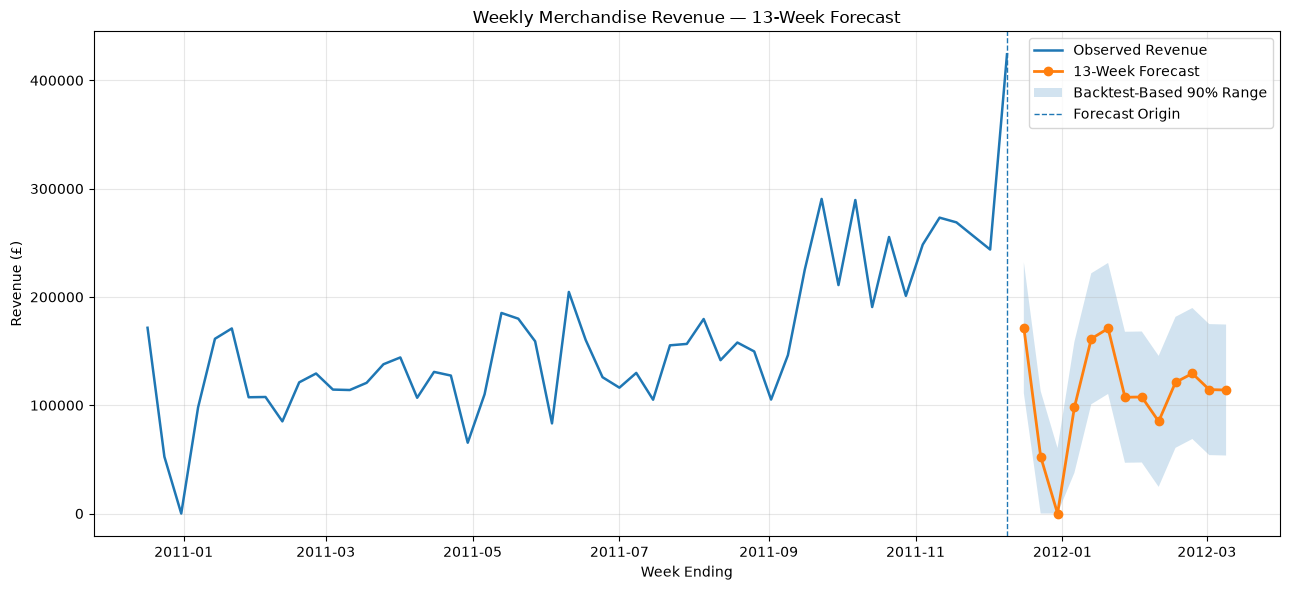

In [27]:
recent_history = (
    weekly_revenue
    .tail(52)
    .copy()
)


plt.figure(
    figsize=(13, 6)
)


# Historical weekly revenue
plt.plot(
    recent_history["week_end"],
    recent_history["revenue"],
    label="Observed Revenue",
    linewidth=1.8,
)


# Final forecast
plt.plot(
    final_forecast["week_end"],
    final_forecast["forecast_revenue"],
    label="13-Week Forecast",
    linewidth=2,
    marker="o",
)


# Empirical uncertainty range
plt.fill_between(
    final_forecast["week_end"],
    final_forecast["lower_90"],
    final_forecast["upper_90"],
    alpha=0.2,
    label="Backtest-Based 90% Range",
)


# Mark the forecast origin.
plt.axvline(
    weekly_revenue["week_end"].max(),
    linestyle="--",
    linewidth=1,
    label="Forecast Origin",
)


plt.title(
    "Weekly Merchandise Revenue — 13-Week Forecast"
)

plt.xlabel(
    "Week Ending"
)

plt.ylabel(
    "Revenue (£)"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

### Final Forecast Visualization — Interpretation

The final forecast preserves the strong annual seasonal pattern identified in the historical data.

Revenue is expected to decline sharply around the year-end holiday period before returning to a more typical weekly range during January and February.

The large difference between the final observed week and the beginning of the forecast illustrates why simple trend extrapolation performed poorly: recent revenue was unusually high relative to the corresponding seasonal period.

The shaded region represents the empirical uncertainty observed during historical backtesting. Forecast uncertainty remains substantial, so the point estimates should be interpreted as planning estimates rather than guaranteed future revenue.

## 5.10 Forecasting Limitations

The revenue forecast should be interpreted with several important limitations:

- The dataset provides only about **two years of transaction history**, which limits the number of repeated annual seasonal cycles available for model estimation and validation.

- The 52-week seasonality assessment is based on only **53 comparable week pairs**.

- A 52-week Seasonal Naive model assumes that the corresponding week one year earlier is a useful proxy for future revenue. Holiday timing, promotions, unusual events, and changes in customer behavior can cause this relationship to shift between years.

- One future week receives a £0 point forecast because the corresponding historical week also contained zero qualifying merchandise revenue. This represents the behavior of the forecasting rule rather than certainty that future revenue would literally be zero.

- The empirical uncertainty range uses the **90th percentile of historical absolute forecast errors**. It is a practical planning range rather than a formally calibrated probabilistic prediction interval.

- The uncertainty margin is applied equally to every forecast week and therefore does not model changes in uncertainty across the forecast horizon.

- LightGBM was trained on a relatively small number of weekly observations, limiting the benefit of nonlinear machine-learning modeling.

- Full 52-week seasonal ETS or SARIMA models were not estimated because the rolling training windows did not contain enough repeated annual cycles to estimate large seasonal structures reliably.

- Revenue forecasts are based on the cleaned qualifying merchandise-purchase table. Returns, cancellations, and non-merchandise transaction codes are not included.

- The models use historical transaction behavior only and do not incorporate external drivers such as promotions, pricing changes, economic conditions, inventory availability, or marketing activity.

## 5.11 Phase 5 Takeaway

Revenue forecasting was evaluated at daily and weekly frequencies before model development.

Weekly revenue was selected because it provided a stronger balance between sample size and stability:

- **105 complete weekly observations**;
- only **1.90%** zero-revenue periods;
- substantially lower relative volatility than the daily series.

A meaningful annual seasonal relationship was identified, with a **52-week revenue correlation of 0.785**.

Four forecasting approaches were then compared using four rolling-origin validation windows and a 13-week forecast horizon:

| Model | MAE | RMSE | sMAPE |
|---|---:|---:|---:|
| Seasonal Naive (52-week) | £30,106.90 | £44,972.90 | 18.22% |
| ARIMA(1,0,0) | £56,555.01 | £77,595.31 | 35.63% |
| LightGBM | £60,541.55 | £80,225.80 | 37.80% |
| ETS Damped Trend | £79,384.10 | £101,253.41 | 46.48% |

The **52-week Seasonal Naive model** produced the strongest out-of-sample performance and was retained as the final forecasting approach.

The selected model forecasts approximately **£1.43 million in merchandise revenue over the next 13 weeks**, covering **16 December 2011 through 9 March 2012**.

The result demonstrates that, with limited historical data and strong recurring seasonality, a simple seasonal benchmark can outperform substantially more complex statistical and machine-learning models.